# MaxCut — Fuerza bruta (HamLib)

Enumeración de los $2^n$ particiones; se conserva el corte máximo.

Instancia: **HamLib** `hamlib-maxcut` ([PennyLane Datasets](https://pennylane.ai/datasets/hamlib-maxcut)),
grafo circulante $n=6$ (`circ_offsets-1-2`). Baseline **clásico exacto**.

> En esta POC $n$ es pequeño, así que brute force es barato. **No escala** ($O(2^n)$).


In [1]:
import itertools
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


In [2]:
def resolve_maxcut_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        root = base / "Notebooks" / "Optimization" / "MaxCutOptimization"
        if root.is_dir():
            return root
    return Path.cwd().resolve() / "Notebooks" / "Optimization" / "MaxCutOptimization"


MAXCUT_DIR = resolve_maxcut_dir()
INSTANCE_PATH = MAXCUT_DIR / "instance" / "hamlib_maxcut.json"
METRICS_DIR = MAXCUT_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

instance = json.loads(INSTANCE_PATH.read_text())
n = int(instance["n"])
edges = [tuple(e) for e in instance["edges"]]
OPTIMAL_CUT = int(instance["optimal_cut"])
OPTIMAL_BITS = list(instance["optimal_bits"])
nodes = list(range(n))

print(
    f"HamLib MaxCut | index={instance['hamlib_index']} id={instance['hamlib_id']} "
    f"n={n} |E|={len(edges)} optimal_cut={OPTIMAL_CUT}"
)
print("Fuente:", instance["url"])
print("Demo QAOA:", instance["demo_ref"])


def cut_value(bits) -> int:
    return int(sum(1 for a, b in edges if bits[a] != bits[b]))


def is_success(bits) -> bool:
    return cut_value(bits) == OPTIMAL_CUT


def save_maxcut_metrics(payload: dict, filename: str):
    path = METRICS_DIR / filename
    path.write_text(json.dumps(payload, indent=2))
    print("Saved:", path)
    return path


HamLib MaxCut | index=8 id=circ_offsets-1-2 n=6 |E|=12 optimal_cut=8
Fuente: https://pennylane.ai/datasets/hamlib-maxcut
Demo QAOA: https://pennylane.ai/demos/tutorial_qaoa_maxcut


## Resolución y métricas


In [3]:
t0 = time.perf_counter()
best_c, best_b, evaluated = -1, None, 0
for k in range(2 ** n):
    bits = [(k >> i) & 1 for i in range(n)]
    evaluated += 1
    c = cut_value(bits)
    if c > best_c:
        best_c, best_b = c, bits
elapsed = time.perf_counter() - t0
success = is_success(best_b)
print("Solución:", best_b, "cut =", best_c, "óptimo =", OPTIMAL_CUT)

payload = {
    "problem": "maxcut",
    "solver": "brute_force",
    "family": "classical",
    "protocol": {
        "n_runs": 1,
        "method": "enumerate_2^n",
        "sense": "maximize_cut",
        "hamlib_index": instance["hamlib_index"],
        "hamlib_id": instance["hamlib_id"],
    },
    "instance": {"n": n, "edges": [list(e) for e in edges], "source": instance["source"]},
    "quality": {
        "optimal_cost": float(OPTIMAL_CUT),
        "optimal_bits": OPTIMAL_BITS,
        "cost_mean": float(best_c),
        "cost_best": float(best_c),
        "gap_mean": float(OPTIMAL_CUT - best_c),
    },
    "success_rate": float(success),
    "time_s": {"mean": float(elapsed), "std": 0.0, "total": float(elapsed)},
    "effort": {"subsets_evaluated": evaluated},
    "runs": [{"seed": 0, "bits": best_b, "cut": float(best_c), "success": bool(success), "time_s": float(elapsed)}],
}
save_maxcut_metrics(payload, "bruteforce_maxcut.json")


Solución: [1, 0, 0, 1, 0, 0] cut = 8 óptimo = 8
Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/metrics/bruteforce_maxcut.json


PosixPath('/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/metrics/bruteforce_maxcut.json')

## Storytelling plots

Figuras para documento/slides → `figures/`.


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/instance_maxcut_graph.png


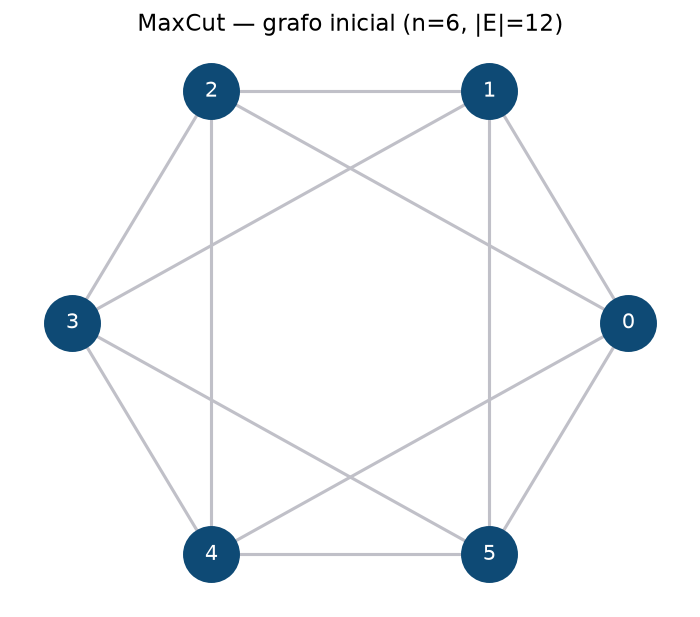

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/bruteforce_maxcut_cut.png


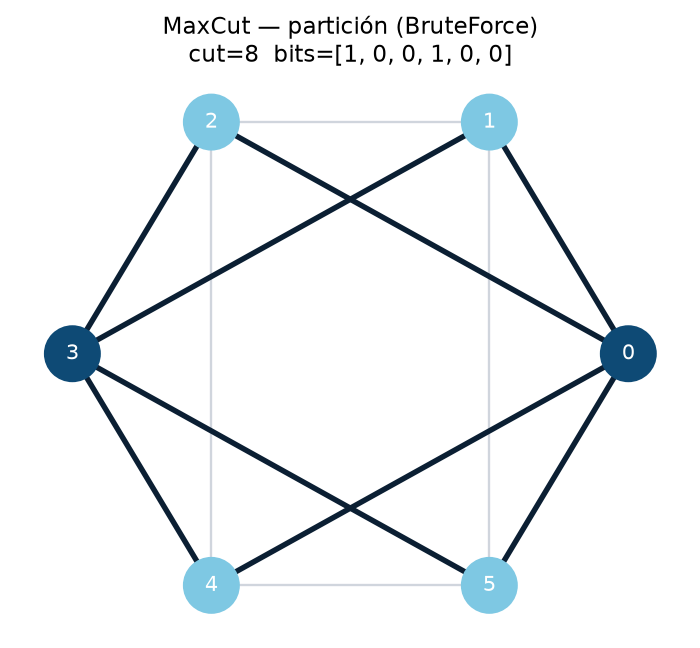

In [4]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import (
    resolve_figures_dir,
    plot_maxcut_instance, plot_maxcut_partition,
)

figures_dir = resolve_figures_dir("Optimization", "MaxCutOptimization")
plot_maxcut_instance(n, edges, figures_dir, stem="instance")
_bits = None
if "payload" in globals() and payload.get("runs"):
    _runs = [r for r in payload["runs"] if r.get("bits") is not None]
    if _runs:
        # MaxCut: higher cut is better
        _bits = max(_runs, key=lambda r: float(r.get("cut", r.get("cost", -1e18)))).get("bits")
if _bits is None and "best_b" in globals() and best_b is not None:
    _bits = best_b
if _bits is None and "bits" in globals() and isinstance(bits, (list, tuple)):
    _bits = bits
if _bits is None and "OPTIMAL_BITS" in globals():
    _bits = OPTIMAL_BITS
if _bits is None:
    raise RuntimeError("No MaxCut bits found for storytelling plot")
plot_maxcut_partition(n, edges, _bits, figures_dir, stem="bruteforce", title="BruteForce")

plt.show()
